In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import os 

os.chdir("/Users/lior/DS6021/DS6021_F26/data")
fram_raw = pd.read_csv("framingham.csv")
#used claude to clean and help with code

645 missing cells total


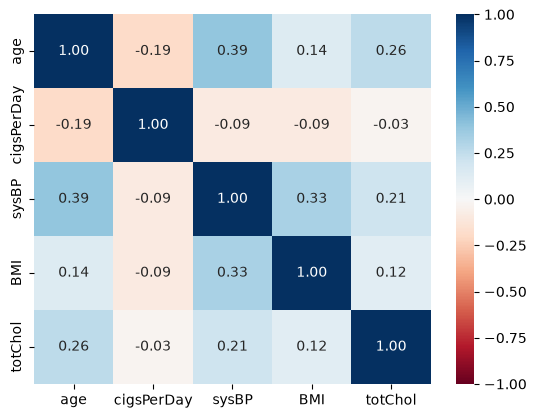

4143.0 829.0


,coef_1,coef_2,se_1,se_2
Intercept,134.233,117.295,5.821,13.051
age,1.152,1.383,0.085,0.192
cigsPerDay,0.112,0.106,0.057,0.125
sysBP,0.221,0.142,0.034,0.077
BMI,0.589,1.114,0.172,0.390


In [5]:
print(fram_raw.isna().sum().sum(), "missing cells total")
corr =fram_raw[['age','cigsPerDay','sysBP','BMI','totChol']].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1); plt.show()

model1 = smf.ols("totChol~age +cigsPerDay+ sysBP+BMI", data=fram_raw).fit()
mf = fram_raw.copy()
mf.loc[mf.sample(frac=0.8, random_state=567).index,'sysBP'] = np.nan
model2 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=mf).fit()
print(model1.nobs,model2.nobs)
pd.DataFrame({"coef_1":model1.params, "coef_2":model2.params, "se_1":model1.bse, "se_2":model2.bse}).round(3)

1a

it fails because framingham has 645 missing values and the linear regression feature in sklearn doesnt accept missing values. We have to drop the rows first because it doesnt drop it for us

1b

the strongest correlatons are age-sysBP and sysBP-BMI and every predicter correlates with totChol at <=0.26 so no predictor is strongly collinear with another and none of them are predictors of cholesterol which is why r2 is low. since sysBP is correlated with BMI and age, it can be predicted from them

1c

it would make it an MCAR because 80 percent of the rows chosen by.sample were at random so if theres a sysBP missing it doesnt depend on it or any other variable or the totChol and every row has the same probability of being erased 

1d

the model uses only about 20 percent of the actual values so the coefficients move but the confidence intervals are wide and model 2 intervals overlap with model 1's. since its MCAR, the estimates are still unbiased and the shifts are sompling noise and not systemic bias

1e

the only mean we can calculate is from the observed value. using the full data mean would include info were pretending is missing and make everyhting look better than it actually could in practice and the observed mean is still an unbiased estumate of the full mean anyway since the data is MCAR